Premiere exploration des données de effectifs

In [323]:
#import des librairies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

Informations générales :
Les données présentent des informations sur les effectifs de patients pris en charge par l'ensemble des régimes d'assurance maladie. Elles sont disponibles par pathologie, traitement chronique ou épisode de soins, sexe, classe d’âge, région et département.

https://data.ameli.fr/explore/assets/effectifs/


In [324]:
df_effectifs = pd.read_csv(
    "../data/raw/Sante/effectifs.csv", sep=';', 
)
df_effectifs.head()

,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,Niveau prioritaire,libelle_classe_age,libelle_sexe,tri
0,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,1,971,280.0,17040,1.643,"2,3",de 50 à 54 ans,femmes,48.0
1,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,3,999,50.0,6090,0.771,"2,3",de 50 à 54 ans,femmes,48.0
2,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,4,974,390.0,32630,1.205,"2,3",de 50 à 54 ans,femmes,48.0
3,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,11,77,350.0,48230,0.732,"2,3",de 50 à 54 ans,femmes,48.0
4,2020,Maladies psychiatriques,Troubles psychotiques,Troubles psychotiques,PSY_PSC_IND,50-54,2,11,91,400.0,43370,0.927,"2,3",de 50 à 54 ans,femmes,48.0


In [325]:
#info generale sur le dataframe
df_effectifs.info()

<class 'pandas.DataFrame'>
RangeIndex: 5796000 entries, 0 to 5795999
Data columns (total 16 columns):
 #   Column              Dtype  
---  ------              -----  
 0   annee               int64  
 1   patho_niv1          str    
 2   patho_niv2          str    
 3   patho_niv3          str    
 4   top                 str    
 5   cla_age_5           str    
 6   sexe                int64  
 7   region              int64  
 8   dept                str    
 9   Ntop                float64
 10  Npop                int64  
 11  prev                float64
 12  Niveau prioritaire  str    
 13  libelle_classe_age  str    
 14  libelle_sexe        str    
 15  tri                 float64
dtypes: float64(3), int64(4), str(9)
memory usage: 707.5 MB


In [326]:
#combien de colonne et de lignes
df_effectifs.shape

(5796000, 16)

Verification la presence des doublons

In [327]:
#reperer les duplicats exactes
df_effectifs.duplicated()

print(df_effectifs.duplicated().sum())

#reperer si il y a une situation qui se repete 
cles = ["annee", "top", "cla_age_5", "sexe", "region", "dept"]

df_effectifs.duplicated(subset=cles).sum()

df_effectifs[
    df_effectifs.duplicated(subset=cles, keep=False)
].sort_values(cles)

0


,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,Niveau prioritaire,libelle_classe_age,libelle_sexe,tri


Verification des valeurs manquantes

In [328]:
#mesurer les valeurs manquantes : afficher le nombre de valeurs manquantes par colonne
df_effectifs.isna().sum()


annee                       0
patho_niv1                  0
patho_niv2             604800
patho_niv3            1310400
top                         0
cla_age_5                   0
sexe                        0
region                      0
dept                        0
Ntop                  1526386
Npop                        0
prev                  1526386
Niveau prioritaire      75600
libelle_classe_age          0
libelle_sexe                0
tri                     75600
dtype: int64

In [329]:
# pourcentage de valeurs manquantes par colonne
valeurs_manquantes = df_effectifs.isna().mean()*100
display(valeurs_manquantes)

annee                  0.000000
patho_niv1             0.000000
patho_niv2            10.434783
patho_niv3            22.608696
top                    0.000000
cla_age_5              0.000000
sexe                   0.000000
region                 0.000000
dept                   0.000000
Ntop                  26.335162
Npop                   0.000000
prev                  26.335162
Niveau prioritaire     1.304348
libelle_classe_age     0.000000
libelle_sexe           0.000000
tri                    1.304348
dtype: float64

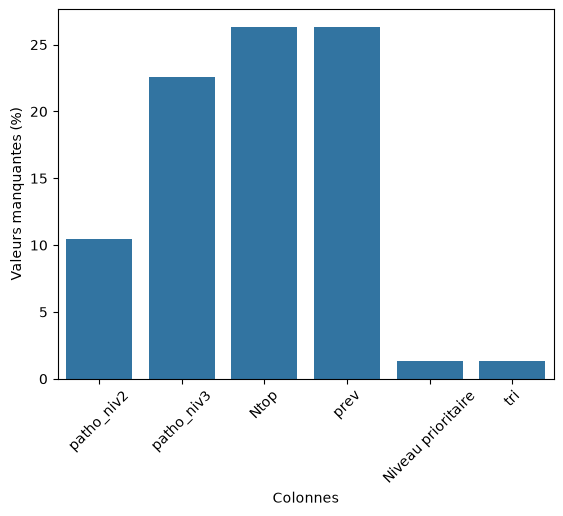

In [330]:
# faire un tableau avec le % des valeurs manquantes

# Garder uniquement les colonnes avec des valeurs manquantes
valeurs_manquantes = valeurs_manquantes[valeurs_manquantes > 0]

# Visualisation
sns.barplot(x=valeurs_manquantes.index, y=valeurs_manquantes.values)
plt.ylabel("Valeurs manquantes (%)")
plt.xlabel("Colonnes")
plt.xticks(rotation=45)
plt.show()

In [331]:
#Valeurs uniques par colonnes
colonnes = df_effectifs.columns.tolist()

df_effectifs[colonnes].nunique()

annee                    10
patho_niv1               18
patho_niv2               48
patho_niv3               61
top                      79
cla_age_5                21
sexe                      3
region                   19
dept                    102
Ntop                  30136
Npop                  16955
prev                  74942
Niveau prioritaire        5
libelle_classe_age       21
libelle_sexe              3
tri                      78
dtype: int64

In [332]:
#quelles sont des valeurs uniques dans la colonne "annee"
print(df_effectifs["annee"].unique())

#quelles sont des valeurs uniques dans la colonne "cla_age_5" et libelle_cla_age_5
print(df_effectifs["cla_age_5"].unique())
print(df_effectifs["libelle_classe_age"].unique())

#quelles sont les  valeurs uniques dans la colonne "sexe" et libelle_sexe
print(df_effectifs["sexe"].unique())
print(df_effectifs["libelle_sexe"].unique())

#quelles sont les  valeurs uniques dans la colonne "Niveau prioritaire"
print(df_effectifs["Niveau prioritaire"].unique())


[2020 2024 2018 2015 2016 2017 2019 2022 2023 2021]
<StringArray>
['50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80-84', '85-89',
 '90-94', '95et+', 'tsage', '00-04', '05-09', '10-14', '15-19', '20-24',
 '25-29', '30-34', '35-39', '40-44', '45-49']
Length: 21, dtype: str
<StringArray>
['de 50 à 54 ans', 'de 55 à 59 ans', 'de 60 à 64 ans', 'de 65 à 69 ans',
 'de 70 à 74 ans', 'de 75 à 79 ans', 'de 80 à 84 ans', 'de 85 à 89 ans',
 'de 90 à 94 ans', 'plus de 95 ans',      'tous âges',   'de 0 à 4 ans',
   'de 5 à 9 ans', 'de 10 à 14 ans', 'de 15 à 19 ans', 'de 20 à 24 ans',
 'de 25 à 29 ans', 'de 30 à 34 ans', 'de 35 à 39 ans', 'de 40 à 44 ans',
 'de 45 à 49 ans']
Length: 21, dtype: str
[2 9 1]
<StringArray>
['femmes', 'tous sexes', 'hommes']
Length: 3, dtype: str
<StringArray>
['2,3', '1,2,3', '3', '1', nan, '2']
Length: 6, dtype: str


In [333]:
#Quelles sont les valeurs uniques pour les pathologies de niveau 1
print(df_effectifs["patho_niv1"].unique())



<StringArray>
[                                                                                         'Maladies psychiatriques',
                                                           'Maladies respiratoires chroniques (hors mucoviscidose)',
                                                                'Maladies inflammatoires ou rares ou infection VIH',
                                                                                           'Maladies neurologiques',
 'Pas de pathologie repérée, traitement, maternité, hospitalisation ou traitement antalgique ou anti-inflammatoire',
                                                                                   'Total consommants tous régimes',
                                                                                                          'Cancers',
                                                                                                          'Diabète',
                                                  

Je selectionne les categories suivantes qui peuvent etre liées à la maladies respiratoires (allergie, asthme, bronchiolite):
maladies respiratoires chroniques (hors mucoviscidose) 
hospitalisation pour Covid-19 (à partir de 2020) 
traitement antalgique ou anti-inflammatoire (hors pathologies, traitements, maternité ou hospitalisations) ;
hospitalisations hors pathologies repérées (avec ou sans pathologies, traitements ou maternité),
Cancers.

In [334]:
# 1. Définir les 5 catégories à explorer
pathologies = [
    "Maladies respiratoires chroniques (hors mucoviscidose)",
    "Hospitalisation pour Covid-19",
    "Traitements antalgiques ou anti-inflammatoires (hors pathologies, traitements, maternité ou hospitalisations)",
    "Hospitalisations hors pathologies repérées (avec ou sans pathologies, traitements ou maternité)",
    "Cancers"
]
pathologie_respi = [
    "Maladies respiratoires chroniques (hors mucoviscidose)"
]

#creation nouvelle df filtré pour 5 categories selectionnées
df_effectifs_filtre = df_effectifs[
    df_effectifs["patho_niv1"].isin(pathologies)
].copy()



#creation nouvelle df filtré pour les maladies respiratoires uniquement

df_respi = df_effectifs[
    df_effectifs["patho_niv1"].isin(pathologie_respi)
]


In [335]:
# Comparer les dimensions
print("Original :", df_effectifs.shape)
print("Filtré :", df_effectifs_filtre.shape)
print("Respi:", df_respi.shape)

Original : (5796000, 16)
Filtré : (1360800, 16)
Respi: (75600, 16)


In [336]:
#verification des souscategories des pathologies

for patho in pathologies:
    print(f"\n--- {patho} ---")

    for col in ["patho_niv2", "patho_niv3"]:
        valeurs = df_effectifs.loc[
            df_effectifs["patho_niv1"] == patho, col
        ].dropna().unique()

        print(f"{col} : {valeurs}")


--- Maladies respiratoires chroniques (hors mucoviscidose) ---
patho_niv2 : <StringArray>
['Maladies respiratoires chroniques (hors mucoviscidose)']
Length: 1, dtype: str
patho_niv3 : <StringArray>
['Maladies respiratoires chroniques (hors mucoviscidose)']
Length: 1, dtype: str

--- Hospitalisation pour Covid-19 ---
patho_niv2 : <StringArray>
['Hospitalisation pour Covid-19']
Length: 1, dtype: str
patho_niv3 : <StringArray>
['Hospitalisation pour Covid-19']
Length: 1, dtype: str

--- Traitements antalgiques ou anti-inflammatoires (hors pathologies, traitements, maternité ou hospitalisations) ---
patho_niv2 : <StringArray>
['Traitements antalgiques ou anti-inflammatoires (hors pathologies, traitements, maternité ou hospitalisations)']
Length: 1, dtype: str
patho_niv3 : <StringArray>
['Traitements antalgiques ou anti-inflammatoires (hors pathologies, traitements, maternité ou hospitalisations)']
Length: 1, dtype: str

--- Hospitalisations hors pathologies repérées (avec ou sans patholog

In [337]:
#selectionner le cancer bronchopulmonaire
df_effectifs_filtre2 = df_effectifs_filtre[
    (df_effectifs_filtre["patho_niv1"] != "Cancers") |
    (df_effectifs_filtre["patho_niv2"] == "Cancer bronchopulmonaire")
].copy()

print("Original :", df_effectifs.shape)
print("Filtré :", df_effectifs_filtre.shape)

print("Filtré2 :", df_effectifs_filtre2.shape)

Original : (5796000, 16)
Filtré : (1360800, 16)
Filtré2 : (529200, 16)


In [338]:
#Afficher le nombre de modalités de sexe, cla_age_5, dept et region  
display(df_effectifs["annee"].value_counts(dropna=False))
display(df_effectifs["sexe"].value_counts(dropna=False))
display(df_effectifs["cla_age_5"].value_counts(dropna=False))
display(df_effectifs["dept"].value_counts(dropna=False))
display(df_effectifs["region"].value_counts(dropna=False))



annee
2020    579600
2024    579600
2018    579600
2015    579600
2016    579600
2017    579600
2019    579600
2022    579600
2023    579600
2021    579600
Name: count, dtype: int64

sexe
9    1990800
2    1915200
1    1890000
Name: count, dtype: int64

cla_age_5
50-54    276000
55-59    276000
60-64    276000
65-69    276000
70-74    276000
75-79    276000
80-84    276000
85-89    276000
90-94    276000
95et+    276000
tsage    276000
00-04    276000
05-09    276000
10-14    276000
15-19    276000
20-24    276000
25-29    276000
30-34    276000
35-39    276000
40-44    276000
45-49    276000
Name: count, dtype: int64

dept
999    917700
971     48300
974     48300
77      48300
91      48300
        ...  
52      48300
11      48300
07      48300
53      48300
04      48300
Name: count, Length: 102, dtype: int64

region
76    676200
75    627900
84    627900
44    531300
11    434700
27    434700
24    338100
93    338100
32    289800
52    289800
28    289800
53    241500
94    144900
1      96600
3      96600
4      96600
2      96600
6      96600
99     48300
Name: count, dtype: int64

In [339]:
# Statistics descriptives pour les colonnes numériques (Ntop, Npop et prev)
df_effectifs[["Ntop", "Npop", "prev"]].describe()

,Ntop,Npop,prev
count,4.269614e+06,5.796000e+06,4.269614e+06
mean,5.560028e+03,1.036321e+05,6.204748e+00
std,1.593980e+05,9.929227e+05,1.593149e+01
min,1.000000e+01,1.000000e+01,0.000000e+00
25%,5.000000e+01,7.740000e+03,2.740000e-01
50%,2.000000e+02,1.709000e+04,9.790000e-01
75%,9.500000e+02,4.285000e+04,4.198000e+00
max,6.882340e+07,6.882340e+07,1.000000e+02


Visualisation des données

Verification des aggregations territoriales: dans la verification des valeurs unique le code 99 et 999 apparaissent, en plus on compte 102 departement et 19 regions au lieux de 101 et 18 officielles

In [340]:
# Vérifier ce que représente le département 999
df_effectifs[
    df_effectifs["dept"] == "999"
][["dept", "region", "annee", "Ntop", "Npop", "prev"]].head(10)

df_effectifs.loc[
    df_effectifs["dept"] == "999", "region"
].unique()

array([ 3, 24, 52, 76,  1,  2,  6, 28, 93, 94,  4, 44, 27, 32, 75, 84, 11,
       53, 99])

999 est probablement un aggregation régionale, qui signifie des donnes totales pour une region (donc plusieurs departements sont y compris)

In [341]:
# Vérifier ce que représente le département 99

df_effectifs.loc[
    df_effectifs["region"] == 99,
    ["region", "dept"]
].drop_duplicates()

,region,dept
355,99,999


99 signifie probablement aggregation nationale

In [342]:
#verifier que  chaque ligne correspond  à une combinaison différente de 
#- Année (annee)
#- Pathologie (top)
#- Classe d'âge (cla_age_5)
#- Sexe (sexe)
df_effectifs.loc[
    (df_effectifs["region"] == 99) &
    (df_effectifs["dept"] == "999"),
    ["annee", "top", "cla_age_5", "sexe", "Ntop", "prev"]
].head(20)

,annee,top,cla_age_5,sexe,Ntop,prev
355,2020,PSY_PSC_IND,65-69,1,15400.0,0.859
395,2020,PSY_PSC_IND,65-69,2,19240.0,0.964
559,2020,PSY_PSC_IND,70-74,9,28890.0,0.797
633,2020,PSY_PSC_IND,75-79,2,10650.0,0.867
793,2020,PSY_PSC_IND,80-84,9,14240.0,0.763
875,2020,PSY_PSC_IND,85-89,2,7770.0,0.864
1138,2020,PSY_PSC_IND,95et+,9,1700.0,0.585
1220,2020,PSY_PSC_IND,tsage,2,210880.0,0.613
1258,2020,PSY_PSC_IND,tsage,9,477820.0,0.724
1561,2020,RES_CAT_EXC,10-14,1,78850.0,3.905


Le jeu de données contient trois niveaux d’agrégation territoriale : départemental, régional et national. Les codes dept = 999 et region ≠ 99 semblent correspondre aux totaux régionaux, tandis que dept = 999 et region = 99 représenteraient le total national (à confirmer dans la documentation). Il faut distinguer ces niveaux lors des analyses pour éviter les doubles comptages.

Niveau d'age il y a plusieurs categories et 1 niveau d'aggregation tous age

et niveau sexe il y a 2 categories et 1 niveau d'aggregation

Donc :
- Analyse départementale → dept != "999"
- Analyse régionale → dept == "999" et region != 99
- Analyse nationale → dept == "999" et region == 99

In [343]:
#3 dataframes territoriaux pour la totalité de df et pour  les maladies respiratoires 

# Départemental total
df_dep= df_effectifs[
    df_effectifs["dept"] != "999"
].copy()

# Départemental respi
df_dept_respi = df_respi[
    df_respi["dept"] != "999"
].copy()

# Régional total
df_reg = df_effectifs[
    (df_effectifs["dept"] == "999") &
    (df_effectifs["region"] != 99)
].copy()

# Régional respi
df_reg_respi = df_respi[
    (df_respi["dept"] == "999") &
    (df_respi["region"] != 99)
].copy()


# National total
df_nat = df_effectifs[
    (df_effectifs["dept"] == "999") &
    (df_effectifs["region"] == 99)
].copy()

# National total respi
df_nat_respi = df_respi[
    (df_respi["dept"] == "999") &
    (df_respi["region"] == 99)
].copy()

df_nat_respi.info()


<class 'pandas.DataFrame'>
Index: 630 entries, 1561 to 5739655
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   annee               630 non-null    int64  
 1   patho_niv1          630 non-null    str    
 2   patho_niv2          630 non-null    str    
 3   patho_niv3          630 non-null    str    
 4   top                 630 non-null    str    
 5   cla_age_5           630 non-null    str    
 6   sexe                630 non-null    int64  
 7   region              630 non-null    int64  
 8   dept                630 non-null    str    
 9   Ntop                630 non-null    float64
 10  Npop                630 non-null    int64  
 11  prev                630 non-null    float64
 12  Niveau prioritaire  630 non-null    str    
 13  libelle_classe_age  630 non-null    str    
 14  libelle_sexe        630 non-null    str    
 15  tri                 630 non-null    float64
dtypes: float64(3), in

In [344]:
import matplotlib.pyplot as plt
import seaborn as sns



1. Évolution annuelle des prévalences 
-a) au niveau national
Question : quelles pathologies représentent les effectifs les plus importants ? - remarque: categorie "total consommant tout regime semble etre un ligne global" - a verifier + cat "pas de categorie repere" cest quoi?
Question : certaines pathologies augmentent-elles ou diminuent-elles dans le temps ?
- b) niveau departementale
- c) niveau regionale

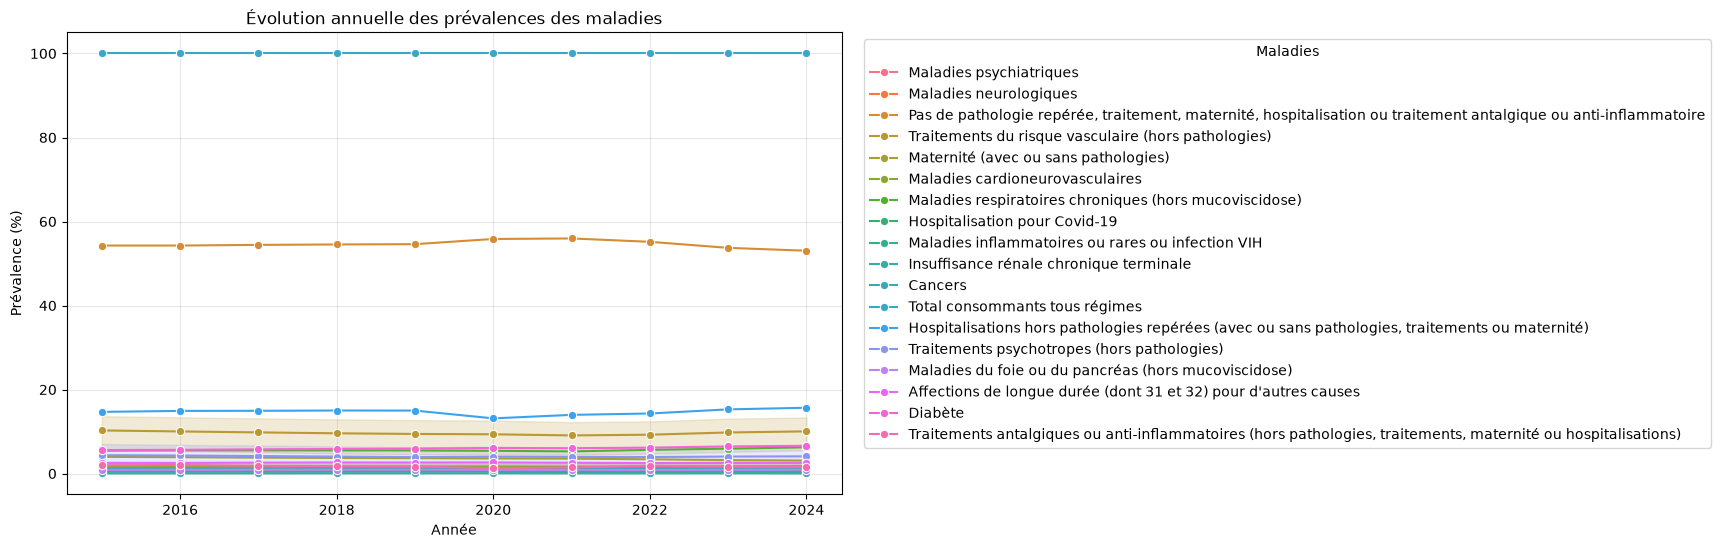

In [345]:
#filtrer sur tsage et tout sexe pour avoir un appercu global niveau national

df_nat_global = df_nat[
    (df_nat["cla_age_5"] == "tsage") &
    (df_nat["sexe"] == 9)
]


#visualisations
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df_nat_global,
    x="annee",
    y="prev",
    hue="patho_niv1",
    marker="o"
)

plt.title("Évolution annuelle des prévalences des maladies")
plt.xlabel("Année")
plt.ylabel("Prévalence (%)")
plt.legend(title="Maladies", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.show()

on remarque que total consommants tous regimes est à 100% tout au long.  Il correspond  probablement à la population totale des personnes ayant consommé au moins un soin remboursé, tous régimes d'assurance maladie confondus. C'est vraisemblablement le dénominateur de référence, et non une pathologie. Il est à exclure des analyses suivantes. 

In [395]:
#verification de categorie "total consommants tous regimes"

tous_regimes = df_nat_global.loc[
    df_nat_global["patho_niv1"].str.contains(
        "Pas de pathologie repérée", case=False, na=False
    ),
    ["annee", "patho_niv1", "prev"]
].drop_duplicates()

display(tous_regimes)

#verification de categorie "Pas de pathologie reperée"
pas_patho = df_nat_global.loc[
    df_nat_global["patho_niv1"].str.contains(
        "Total consommant", case=False, na=False
    ),
    ["annee", "patho_niv1", "prev"]
].drop_duplicates()

display(pas_patho)

,annee,patho_niv1,prev
7979,2020,"Pas de pathologie repérée, traitement, materni...",55.847
843239,2018,"Pas de pathologie repérée, traitement, materni...",54.539
976492,2019,"Pas de pathologie repérée, traitement, materni...",54.611
1316100,2023,"Pas de pathologie repérée, traitement, materni...",53.733
2139280,2022,"Pas de pathologie repérée, traitement, materni...",55.173
2267182,2016,"Pas de pathologie repérée, traitement, materni...",54.283
3232254,2015,"Pas de pathologie repérée, traitement, materni...",54.281
3652718,2021,"Pas de pathologie repérée, traitement, materni...",55.972
5647399,2024,"Pas de pathologie repérée, traitement, materni...",53.046
5731002,2017,"Pas de pathologie repérée, traitement, materni...",54.439


,annee,patho_niv1,prev
255333,2016,Total consommants tous régimes,100.0
730817,2017,Total consommants tous régimes,100.0
872427,2018,Total consommants tous régimes,100.0
962333,2019,Total consommants tous régimes,100.0
1932836,2023,Total consommants tous régimes,100.0
3312421,2015,Total consommants tous régimes,100.0
3568554,2020,Total consommants tous régimes,100.0
4806324,2021,Total consommants tous régimes,100.0
5699875,2024,Total consommants tous régimes,100.0
5763393,2022,Total consommants tous régimes,100.0


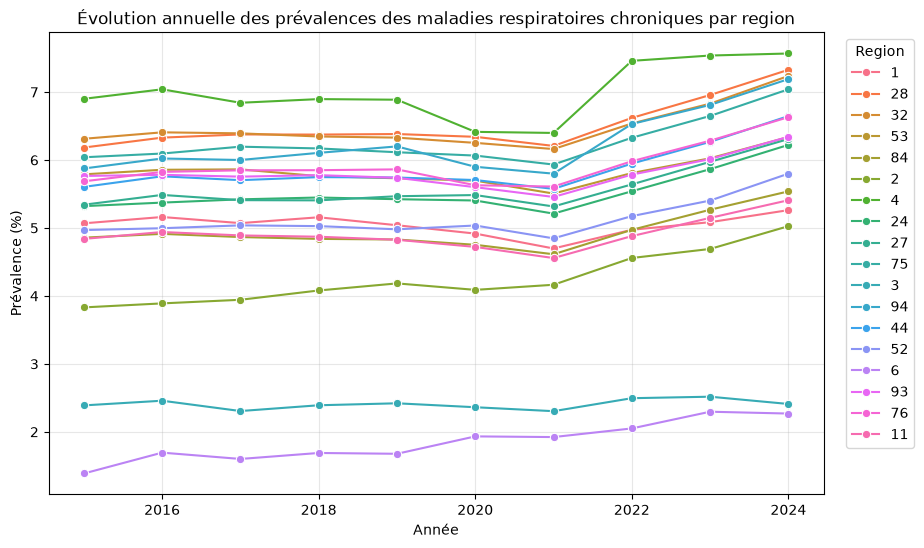

In [346]:
#filtrer sur tsage et tout sexe pour avoir un appercu global niveau regional

df_reg_respi_global = df_reg_respi[
    (df_reg_respi["cla_age_5"] == "tsage") &
    (df_reg_respi["sexe"] == 9)
]


#visualisations
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df_reg_respi_global,
    x="annee",
    y="prev",
    hue=df_reg_respi_global["region"].astype(str),
    marker="o"
)

plt.title("Évolution annuelle des prévalences des maladies respiratoires chroniques par region")
plt.xlabel("Année")
plt.ylabel("Prévalence (%)")
plt.legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.show()

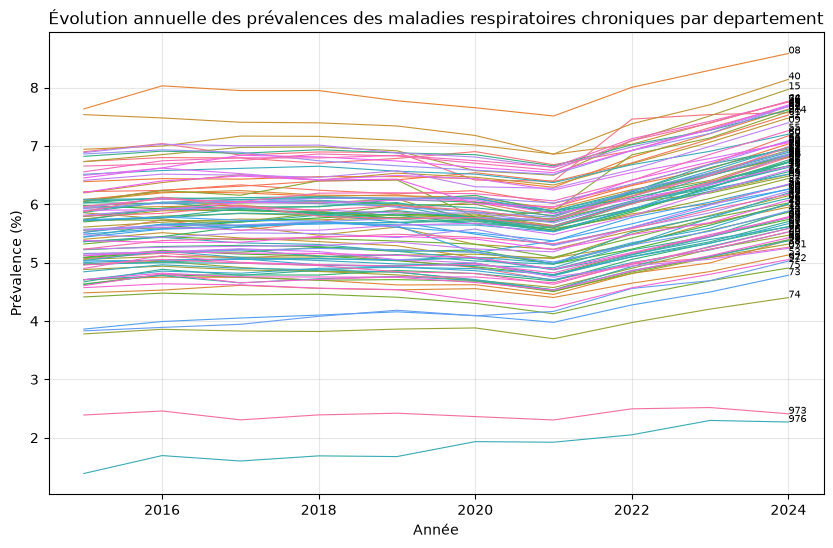

In [347]:
#filtrer sur tsage et tout sexe pour avoir un appercu global niveau departementale

df_dept_respi_global = df_dept_respi[
    (df_dept_respi["cla_age_5"] == "tsage") &
    (df_dept_respi["sexe"] == 9)
]


#visualisations
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=df_dept_respi_global,
    x="annee",
    y="prev",
    units = "dept",
    estimator=None,
    hue = "dept",
    linewidth=0.8,
    legend=False
)

for dept, groupe in df_dept_respi_global.groupby("dept"):
    groupe = groupe.sort_values("annee").dropna(subset=["prev"])

    if not groupe.empty:
        plt.text(
            groupe["annee"].iloc[-1],
            groupe["prev"].iloc[-1],
            str(dept),
            fontsize=7
        )

plt.legend([], [], frameon=False)

plt.title("Évolution annuelle des prévalences des maladies respiratoires chroniques par departement")
plt.xlabel("Année")
plt.ylabel("Prévalence (%)")
plt.grid(alpha=0.3)
plt.show()

Distribution annuelle des maladies respiratoires - les regions evoluent ils ensemble?

,count,mean,std,min,25%,50%,75%,max
annee,,,,,,,,
2015,101.0,5.525,0.911,1.387,5.034,5.571,6.026,7.634
2016,101.0,5.621,0.910,1.694,5.121,5.692,6.104,8.029
2017,101.0,5.616,0.929,1.601,5.071,5.696,6.075,7.948
2018,101.0,5.618,0.920,1.689,5.071,5.711,6.123,7.948
2019,101.0,5.608,0.913,1.677,5.034,5.747,6.101,7.773
2020,101.0,5.537,0.884,1.933,4.989,5.697,6.073,7.653
2021,101.0,5.398,0.872,1.923,4.825,5.549,5.887,7.512
2022,101.0,5.757,0.925,2.050,5.156,5.890,6.237,8.003
2023,101.0,6.053,0.962,2.296,5.449,6.213,6.608,8.296


[Text(0.5, 0, 'Année'),
 Text(0, 0.5, 'Prévalence publiée (%)'),
 Text(0.5, 1.0, 'Dispersion départementale')]

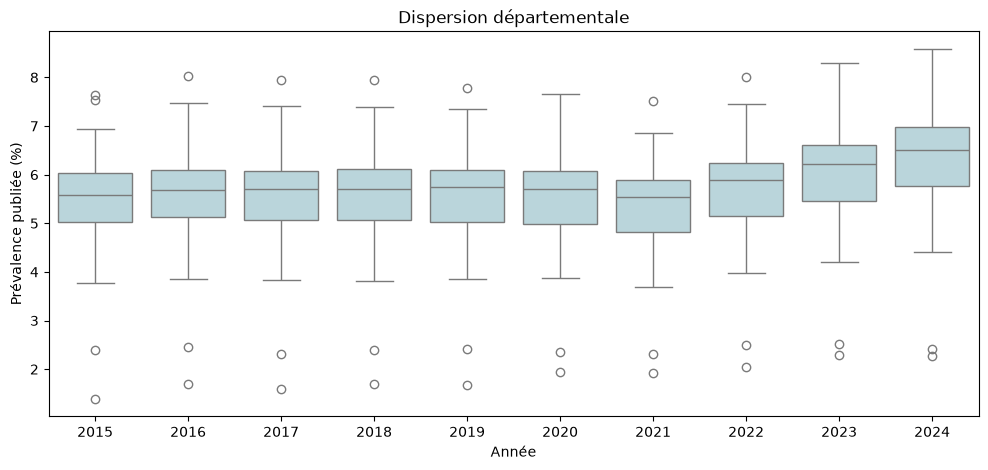

In [351]:

df_dept_respi_global = df_dept_respi[
    (df_dept_respi["cla_age_5"] == "tsage") &
    (df_dept_respi["sexe"] == 9)
]
display(df_dept_respi_global.groupby('annee')['prev'].describe().round(3))
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df_dept_respi_global, x='annee', y='prev', ax=ax, color="#b5d8e0")
ax.set(xlabel='Année', ylabel='Prévalence publiée (%)', title='Dispersion départementale')


Prevalance plus hautes et plus basses par departement Top 10 over the years

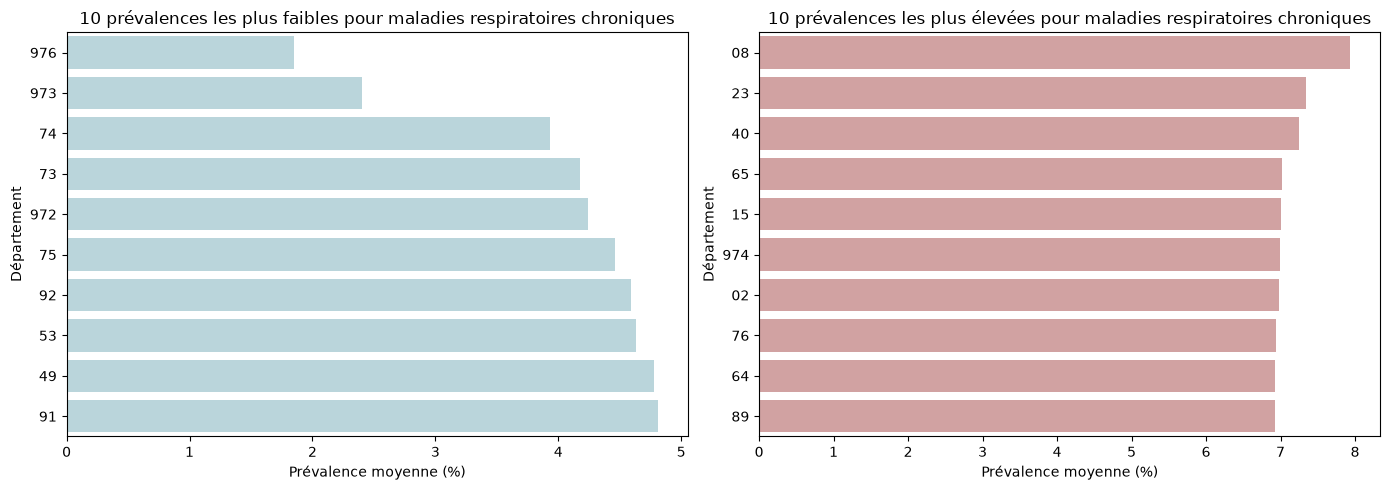

In [353]:
# Prévalence moyenne par département
prev_dept = df_dept_respi_global.groupby("dept")["prev"].mean().sort_values()

# 10 plus faibles et 10 plus élevées
top10_bas = prev_dept.head(10)
top10_haut = prev_dept.tail(10).sort_values(ascending=False)

# Deux graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=top10_bas.values, y=top10_bas.index.astype(str),
            ax=axes[0], color="#b5d8e0", orient="h")

sns.barplot(x=top10_haut.values, y=top10_haut.index.astype(str),
            ax=axes[1], color="#d99a9a", orient="h")

axes[0].set(title="10 prévalences les plus faibles pour maladies respiratoires chroniques",
            xlabel="Prévalence moyenne (%)", ylabel="Département")

axes[1].set(title="10 prévalences les plus élevées pour maladies respiratoires chroniques",
            xlabel="Prévalence moyenne (%)", ylabel="Département")

plt.tight_layout()
plt.show()

5. Heatmap : départements × années
Question : comment les effectifs évoluent-ils selon les territoires ?

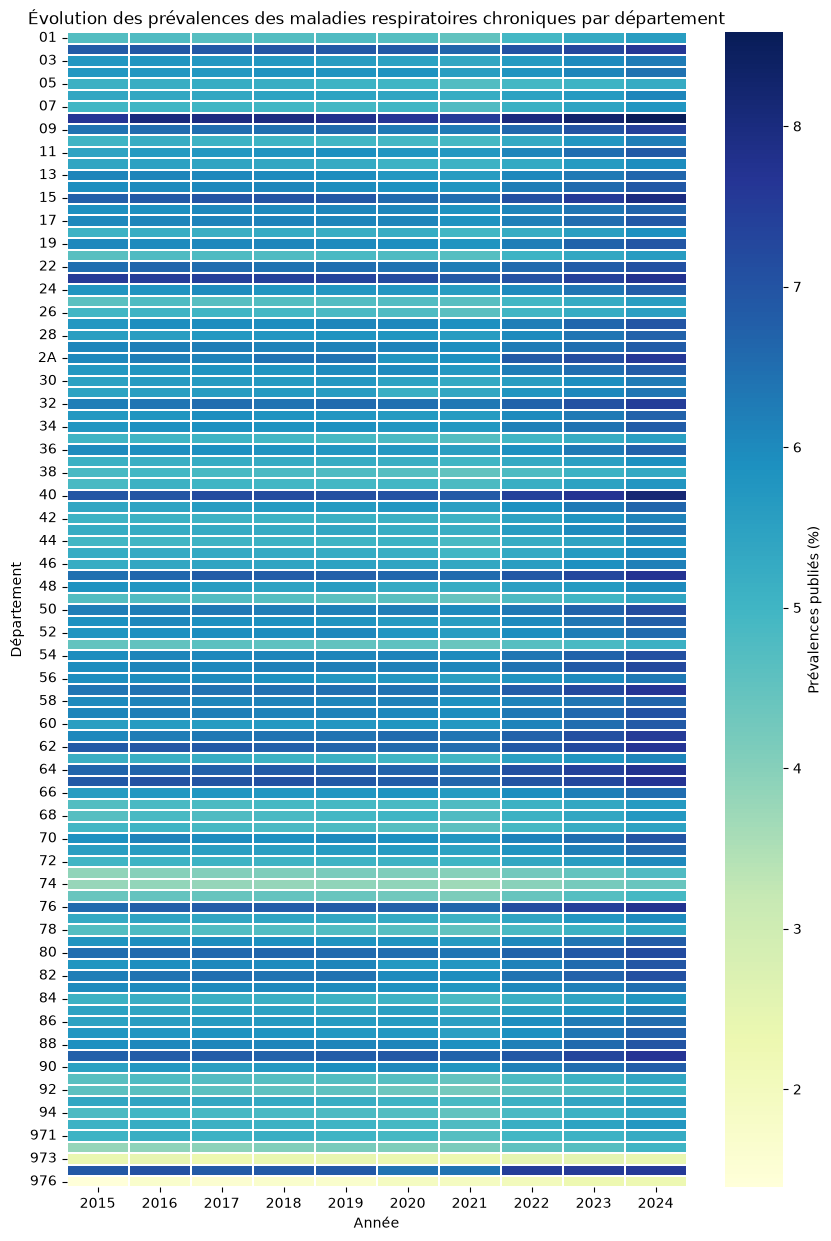

In [360]:
# Préparer les données - j'utilise pivot_table  car plus adapté pour resumer les valeurs numeriques 

heatmap_data = df_dept_respi_global.pivot_table(
    index="dept",
    columns="annee",
    values="prev",
    aggfunc="mean"
)

# Visualisation
plt.figure(figsize=(10, 15))

sns.heatmap(
    heatmap_data,
    cmap='YlGnBu',
    linewidths=0.2,
    cbar_kws={"label": "Prévalences publiés (%)"}
)

plt.title("Évolution des prévalences des maladies respiratoires chroniques par département")
plt.xlabel("Année")
plt.ylabel("Département")
plt.show()

## 13. Âge et sexe : comparer des strates distinctes
On choisit un année
Les lignes « tous âges » et « tous sexes » sont exclues.
Pour chaque âge/sexe, le graphique montre la médiane des prévalences départementales disponibles.
Le nombre de départements est affiché dans le tableau 

,annee,patho_niv1,patho_niv2,patho_niv3,top,cla_age_5,sexe,region,dept,Ntop,Npop,prev,Niveau prioritaire,libelle_classe_age,libelle_sexe,tri
38778,2024,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,RES_CAT_EXC,85-89,1,32,02,700.0,3770,18.503,"1,2,3",de 85 à 89 ans,hommes,10.0
38780,2024,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,RES_CAT_EXC,85-89,1,44,10,350.0,2620,13.354,"1,2,3",de 85 à 89 ans,hommes,10.0
38781,2024,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,RES_CAT_EXC,85-89,1,44,52,280.0,1770,15.971,"1,2,3",de 85 à 89 ans,hommes,10.0
38782,2024,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,RES_CAT_EXC,85-89,1,44,67,1270.0,8750,14.485,"1,2,3",de 85 à 89 ans,hommes,10.0
38783,2024,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,Maladies respiratoires chroniques (hors mucovi...,RES_CAT_EXC,85-89,1,44,08,390.0,2190,17.986,"1,2,3",de 85 à 89 ans,hommes,10.0


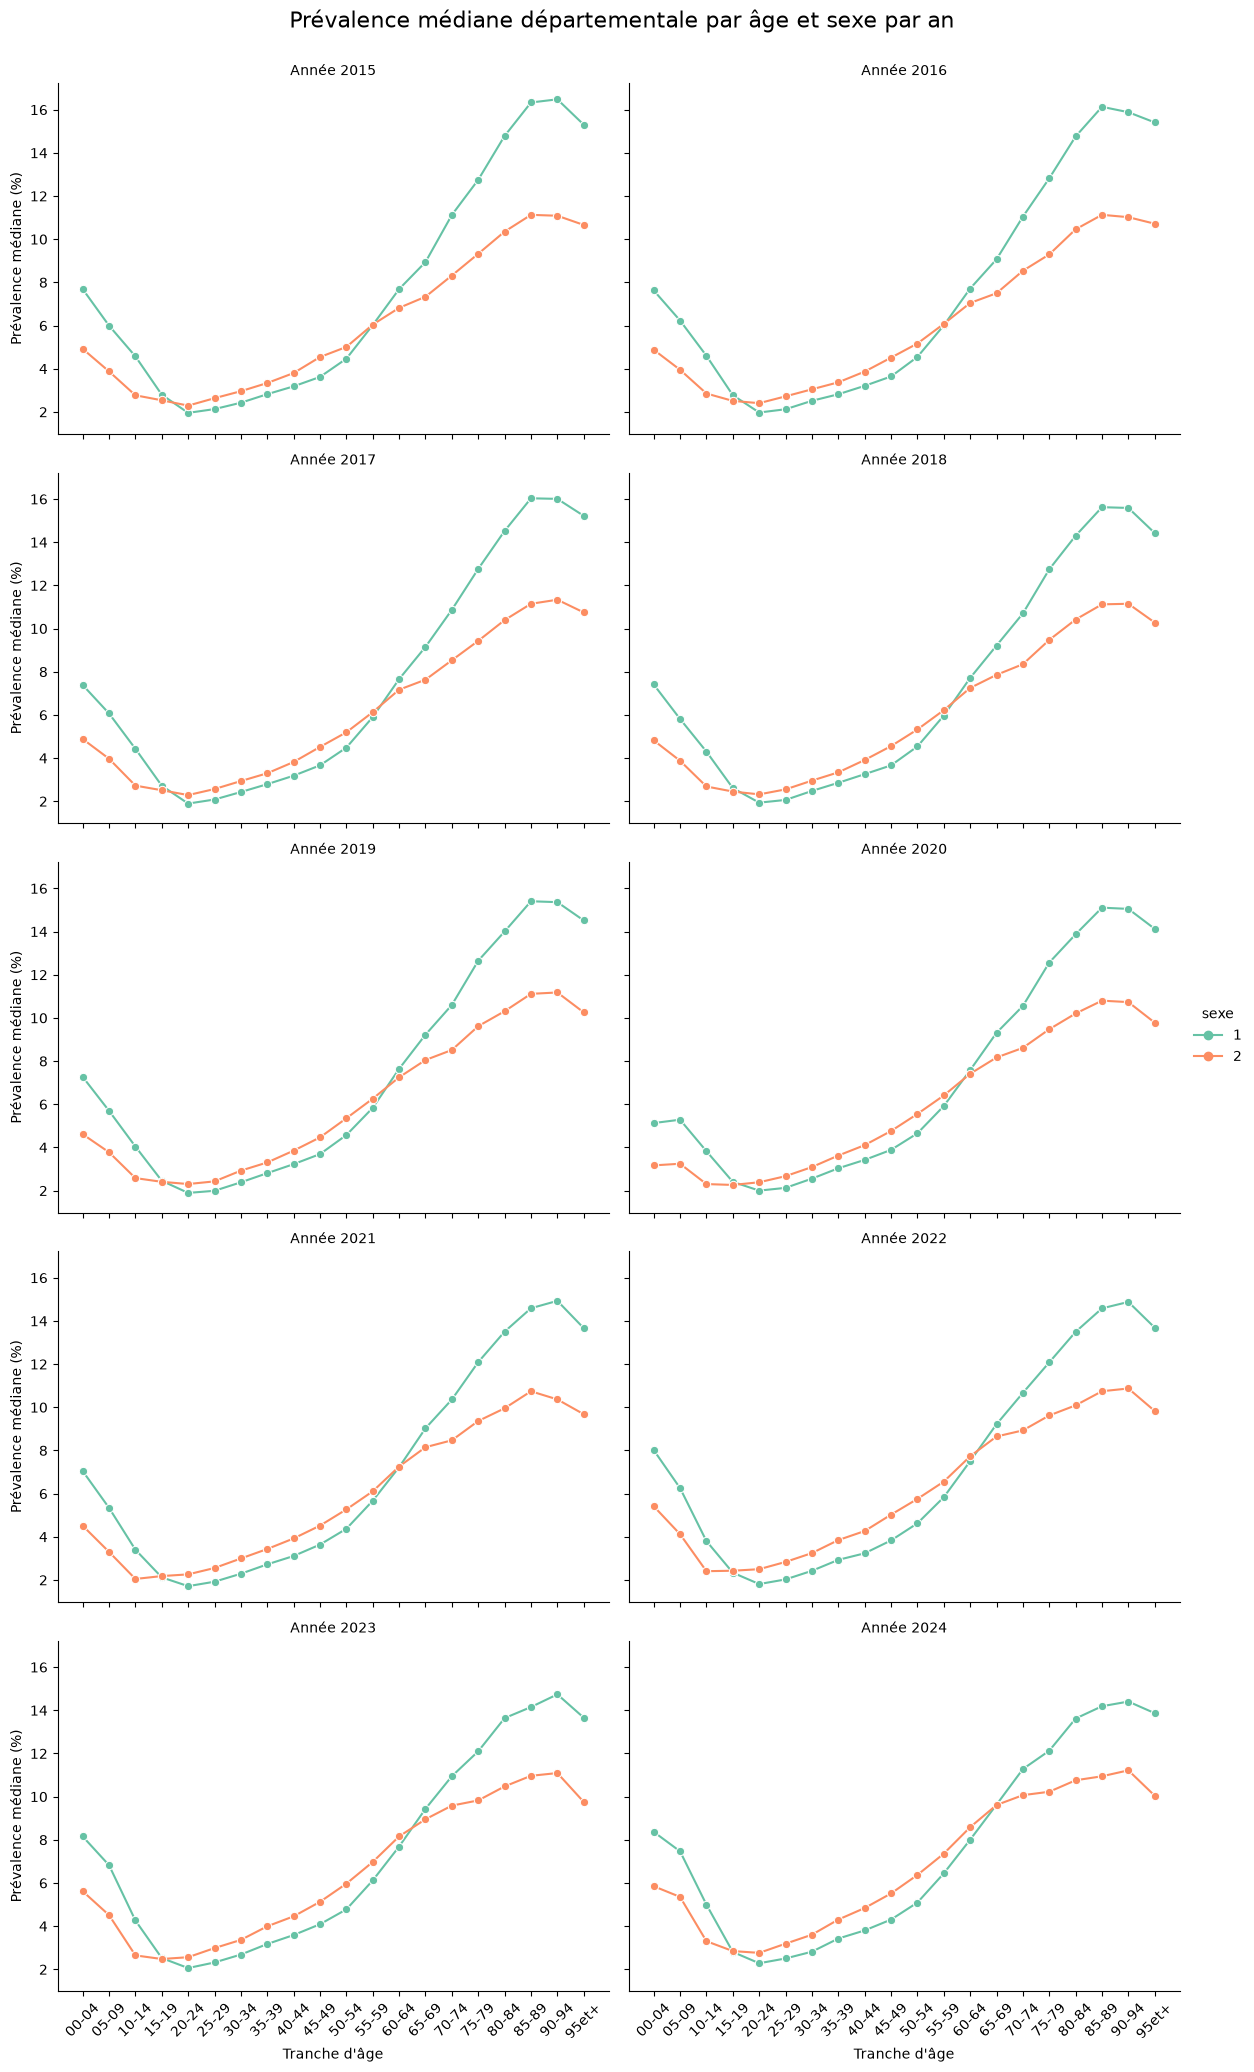

In [ ]:
#j'exclue les lignes tous sexes et tous ages
df_age_sex2 = df_dept_respi[(df_dept_respi["sexe"] != 9) &
                           (df_dept_respi["cla_age_5"] != "tsage") 
                           ]


display(df_age_sex.head(5))

#mettre en ordre les classes d'ages 
ordre_ages = sorted(df_age_sex2["cla_age_5"].unique())

df_age_sex2["cla_age_5"] = pd.Categorical(
    df_age_sex2["cla_age_5"],
    categories=ordre_ages,
    ordered=True
)


g = sns.relplot(
    data=df_age_sex2,  
    x="cla_age_5",
    y="prev",
    hue="sexe",
    col="annee",
    col_wrap=2,         # 2 graphiques par ligne
    kind="line",
    estimator="median", #calculer le mediane des prevalence pour toutles departement par tranche d'age et sexe par seaborn estimator = "median"
    errorbar=None,
    marker="o",
    palette="Set2",
    height=4,
    aspect=1.5,
    facet_kws={"sharey": True}
)

g.set_axis_labels("Tranche d'âge", "Prévalence médiane (%)")
g.set_titles("Année {col_name}")
g.tick_params(axis="x", rotation=45)
g.fig.suptitle("Prévalence médiane départementale par âge et sexe par an", fontsize=16, y=1.02)


plt.show()